In [1]:
#Import necessary Librry
import os
import time
import numpy as np
import pandas as pd

import numpy as np
from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, classification_report, accuracy_score
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
import joblib

import mne

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.regularizers import l2
from keras import backend as K
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dropout,\
 Flatten, Dense, Reshape, LSTM,  SimpleRNN, GRU, Bidirectional, Activation

from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten,\
 BatchNormalization,  DepthwiseConv2D, AveragePooling2D, SeparableConv2D

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
#from wandb.integration.keras import WandbCallback
import warnings
warnings.filterwarnings('ignore')

In [2]:
for dirname, _, filenames in os.walk('EEG_80'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

EEG_80\1.csv
EEG_80\10.csv
EEG_80\11.csv
EEG_80\12.csv
EEG_80\13.csv
EEG_80\14.csv
EEG_80\15.csv
EEG_80\16.csv
EEG_80\17.csv
EEG_80\18.csv
EEG_80\19.csv
EEG_80\2.csv
EEG_80\20.csv
EEG_80\21.csv
EEG_80\22.csv
EEG_80\23.csv
EEG_80\24.csv
EEG_80\25.csv
EEG_80\26.csv
EEG_80\27.csv
EEG_80\28.csv
EEG_80\29.csv
EEG_80\3.csv
EEG_80\30.csv
EEG_80\31.csv
EEG_80\32.csv
EEG_80\33.csv
EEG_80\34.csv
EEG_80\35.csv
EEG_80\36.csv
EEG_80\37.csv
EEG_80\38.csv
EEG_80\39.csv
EEG_80\4.csv
EEG_80\40.csv
EEG_80\41.csv
EEG_80\42.csv
EEG_80\43.csv
EEG_80\44.csv
EEG_80\45.csv
EEG_80\46.csv
EEG_80\47.csv
EEG_80\48.csv
EEG_80\49.csv
EEG_80\5.csv
EEG_80\50.csv
EEG_80\51.csv
EEG_80\52.csv
EEG_80\53.csv
EEG_80\54.csv
EEG_80\55.csv
EEG_80\56.csv
EEG_80\57.csv
EEG_80\58.csv
EEG_80\59.csv
EEG_80\6.csv
EEG_80\60.csv
EEG_80\61.csv
EEG_80\62.csv
EEG_80\63.csv
EEG_80\64.csv
EEG_80\65.csv
EEG_80\66.csv
EEG_80\67.csv
EEG_80\68.csv
EEG_80\69.csv
EEG_80\7.csv
EEG_80\70.csv
EEG_80\71.csv
EEG_80\72.csv
EEG_80\73.csv
EEG_80\74.csv

In [3]:
column_list = pd.read_csv("EEG_80/columnLabels.csv").columns
electrode = pd.read_csv("EEG_80/columnLabels.csv").columns[4:]

In [4]:
demographic = pd.read_csv("EEG_80/demographic.csv")

In [5]:
for i, t in enumerate(list(demographic[" group"])):
  demographic["Patient"] = np.where(demographic[" group"] == 0, "Healthy","Schizoprnia")
  demographic["Patient"] = np.where(demographic[" group"] == 1, "Schizoprnia", "Helathy")

In [6]:
count = demographic.groupby(["Patient"], as_index = False)["subject"].count()
count

,Patient,subject
0,Helathy,32
1,Schizoprnia,49


In [7]:
# dict for data preprocessing
dict_ = dict(zip(demographic["subject"], demographic[" group"]))

In [8]:
time = pd.read_csv("EEG_80/time.csv")
time.head()

,sample,time_ms
0,1,-1500.0000
1,2,-1499.0234
2,3,-1498.0469
3,4,-1497.0703
4,5,-1496.0938


In [9]:
def average(m, n):
    shape = m.shape
    assert len(shape) == 2
    assert shape[0] % n == 0
    a = m.reshape(shape[0] // n, n,
                  shape[1])
    mean_vector = a.mean(axis=1)
    return mean_vector

In [10]:
n = 16
x_count = 0
X = np.zeros((81 * 100,  9216 * len(electrode) // n), dtype="float32")
Y = np.zeros(len(X))

part1_path = "EEG_80"



column_list = pd.read_csv("EEG_80/columnLabels.csv").columns
for person_num in tqdm(range(1, 82)):


    csv_path = f"{part1_path}/{person_num}.csv"

    df = pd.read_csv(csv_path,
                header=None,
                names=column_list)
    trial_list = set(df.trial)


    for t1, trial_number in enumerate(trial_list):
        trials = len(df[df.trial == trial_number])
        if trials == 9216.0:
            matrix = df[df.trial == trial_number][electrode].values
            averaged = average(matrix, n = n)
            averaged_N = averaged.reshape(-1)
            X[x_count] = averaged_N.astype(np.float32)
            Y[x_count] = dict_[person_num]
            x_count += 1

X = X[: x_count]
Y = Y[: x_count]
print("Total trials for X - ", x_count)
print("Total trials for Y- ", x_count)

  0%|          | 0/81 [00:00<?, ?it/s]

Total trials for X -  7092
Total trials for Y-  7092


In [11]:
#Normalization

X_norm = (normalize(X.reshape(-1, 70), axis=0, norm='max')).reshape(X.shape)
X_norm.shape

(7092, 40320)

In [12]:
#Train test split
X_train, X_test, Y_train, Y_test = train_test_split(X_norm, Y, test_size=0.2, shuffle=True, random_state=42)

In [13]:
X_train_1d = X_train.reshape(-1, 576, 70)
X_test_1d = X_test.reshape(-1, 576, 70)

ReLu

In [14]:
CNN = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ReLu\CNN_1D.keras')
GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ReLu\GRU.keras')
CNN_LSTM = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ReLu\cnn_lstm.keras')
CNN_GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ReLu\cnn_gru.keras')
CNN_LSTM_GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ReLu\CNN_LSTM_GRU.keras')

178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 28s 157ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step


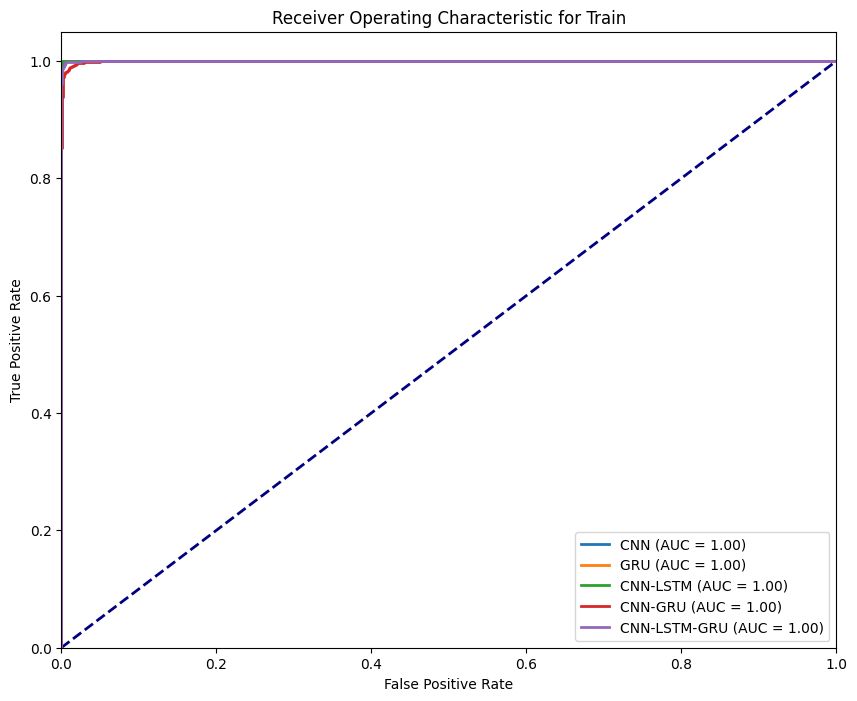

In [15]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "GRU": GRU,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_train_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_train, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for Train')
plt.legend(loc="lower right")
plt.show()

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step


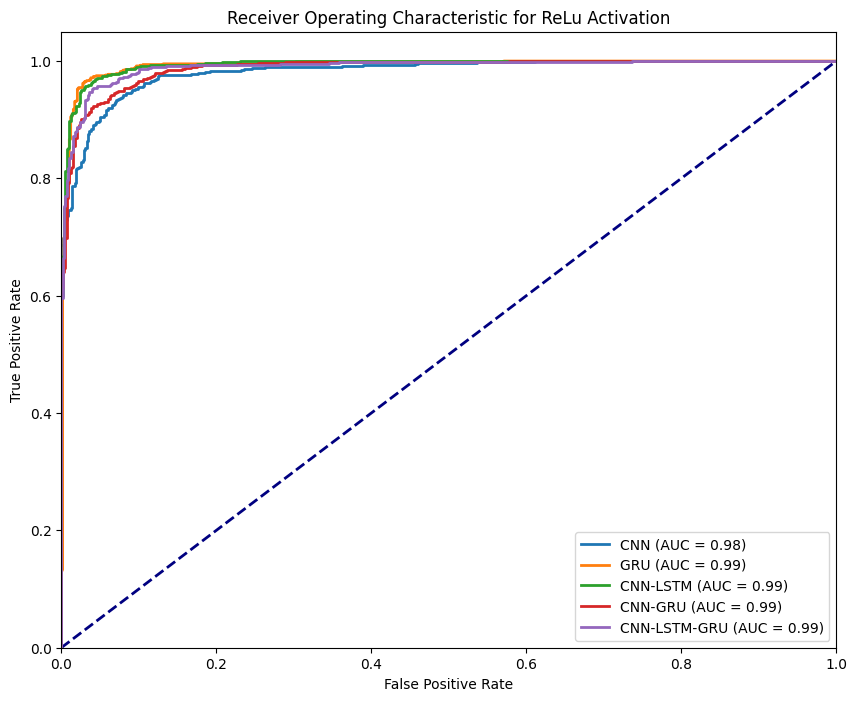

In [16]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "GRU": GRU,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_test_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for ReLu Activation')
plt.legend(loc="lower right")
plt.show()

ELU

In [17]:
CNN = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ELU\CNN_1D.keras')
GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ELU\GRU.keras')
CNN_LSTM = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ELU\cnn_lstm.keras')
CNN_GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ELU\cnn_gru.keras')
CNN_LSTM_GRU = load_model('E:\Schizophrenia_EEG\DL Model\80 and 20 ELU\CNN_LSTM_GRU.keras')

178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 27s 153ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step


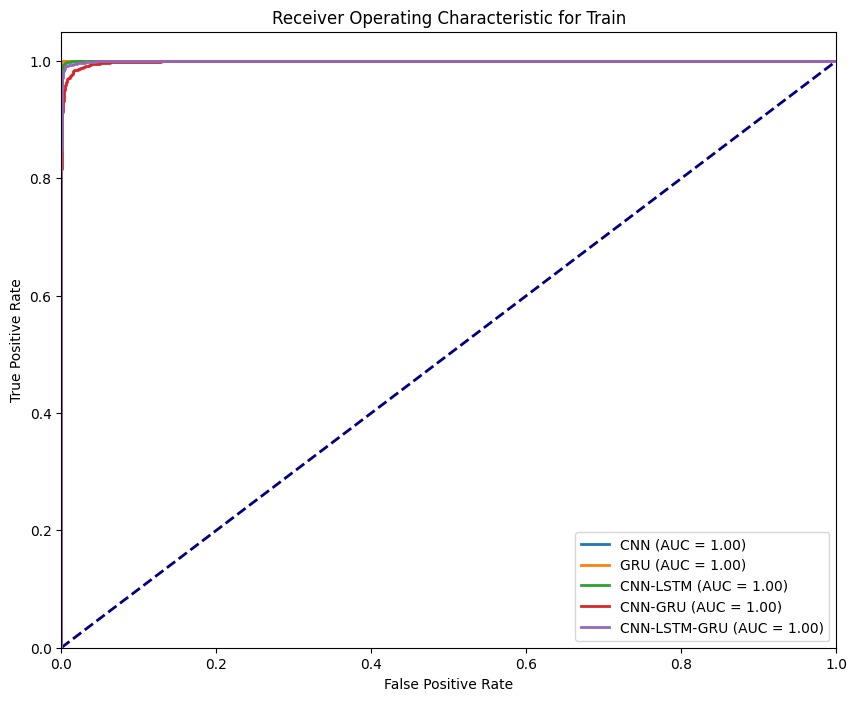

In [18]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "GRU": GRU,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_train_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_train, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for Train')
plt.legend(loc="lower right")
plt.show()

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 157ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step


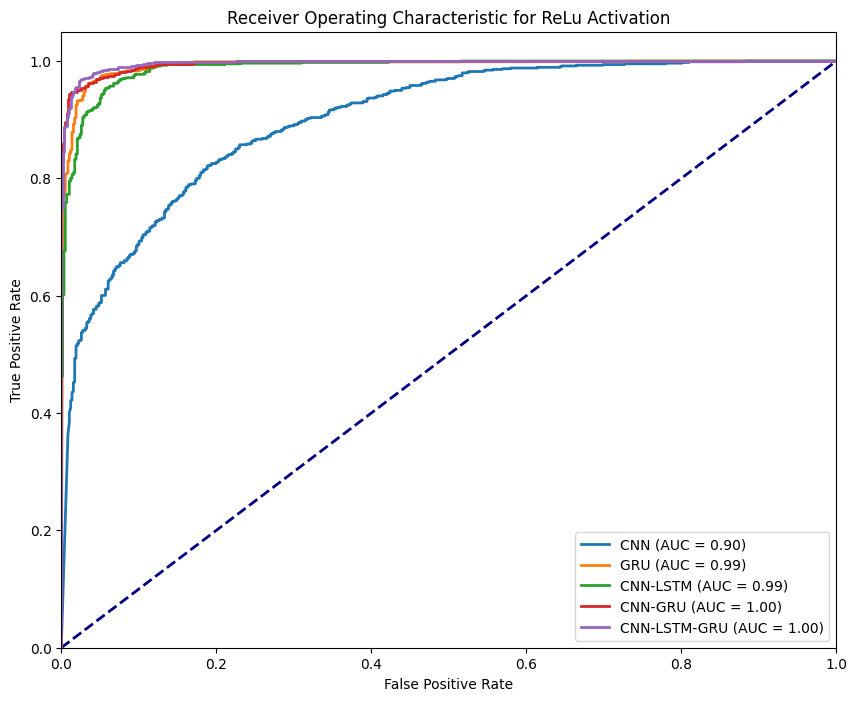

In [19]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "GRU": GRU,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_test_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for ReLu Activation')
plt.legend(loc="lower right")
plt.show()